# Decision Trees Exercises

![DecisionTree.png](Assets/DecisionTree.png)


# Obiectivele cursului

- Recunoașteți arborii de decizie și modul în care aceștia pot fi utilizați pentru probleme de clasificare
- Aflați cum se determină cea mai bună divizare și factorii de divizare
- Explicați punctele forte și punctele slabe ale arborilor de decizie
- Explicați modul în care arborii de regresie ajută la clasificarea valorilor continue





## Introducere

Pentru aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține un indicator al calității (3-9, unde valoarea cea mai mare indică o calitate mai bună) și culoarea (roșu sau alb). Numele fișierului este „Wine_Quality_Data.csv”.

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')
data_path = ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz, plot_tree
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

# sklearnex (Intel Extension) accelereaza sklearn; daca nu este instalat continuam fara el
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('sklearnex nu este instalat - se foloseste scikit-learn standard')

sklearnex nu este instalat - se foloseste scikit-learn standard


## Întrebarea 1

* Importați datele și studiați funcțiile.
* Le vom folosi pe toate pentru a prezice `color` (alb sau roșu), dar funcția culorilor trebuie codificată ca număr întreg.

In [2]:
# Citim datele
filepath = 'Wine_Quality_Data - Wine_Quality_Data.csv'
data = pd.read_csv(filepath)

print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
# Tipurile de date ale caracteristicilor
data.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object

Convertiți funcția de culoare într-un număr întreg. Iată o metodă rapidă de a face acest lucru folosind Pandas.

In [4]:
# Codificam culoarea ca intreg: white = 0, red = 1
data['color'] = data.color.replace('white', 0).replace('red', 1).astype(int)
data['color'].value_counts()

color
0    4898
1    1599
Name: count, dtype: int64

In [5]:
# Toate coloanele, cu exceptia 'color', sunt caracteristici
feature_cols = [x for x in data.columns if x not in 'color']
print(feature_cols)

['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


## Întrebarea 2

* Utilizați `StratifiedShuffleSplit` pentru a împărți datele în seturi de trenuri și de teste, stratificate în funcție de calitatea vinului. Dacă este posibil, păstrați indicii privind ponderea pentru întrebarea 5 de mai jos.
* Verificați compoziția procentuală a fiecărui nivel de calitate pentru seturile de date privind trenurile și datele de testare.

In [6]:
# Impartim datele: 1000 de observatii pentru test, stratificat dupa calitatea vinului
strat_shuff_split = StratifiedShuffleSplit(n_splits=1, test_size=1000, random_state=42)

# Salvam indicii pentru a-i refolosi la intrebarea 5
train_idx, test_idx = next(strat_shuff_split.split(data[feature_cols], data['quality']))

# Seturile de antrenare si test
X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'color']

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'color']

print(X_train.shape, X_test.shape)

(5497, 12) (1000, 12)


In [7]:
# Compozitia procentuala a fiecarui nivel de calitate in train si test
pd.DataFrame({'train (%)': (data.loc[train_idx, 'quality'].value_counts(normalize=True).sort_index() * 100).round(2),
              'test (%)': (data.loc[test_idx, 'quality'].value_counts(normalize=True).sort_index() * 100).round(2)})

,train (%),test (%)
quality,,
3,0.45,0.5
4,3.33,3.3
5,32.91,32.9
6,43.66,43.6
7,16.61,16.6
8,2.97,3.0
9,0.07,0.1


**Concluzie:** procentele pentru fiecare nivel de calitate sunt practic identice in setul de antrenare si in cel de test, deci stratificarea a functionat.

## Întrebarea 3

* Construiți un clasificator pe baza unui arbore de decizie, fără restricții privind adâncimea maximă, numărul de caracteristici sau numărul de frunze.
* Determinați câte noduri sunt prezente în acest arbore (foarte mare) și care este adâncimea acestuia.
* Folosind acest arbore, evaluați eroarea de predicție pe seturile de date de antrenare și de testare. Ce credeți că se întâmplă aici, pe baza diferențelor dintre erorile de predicție?

In [8]:
# Arbore de decizie fara restrictii
dt = DecisionTreeClassifier(random_state=42)
dt = dt.fit(X_train, y_train)

print('Numar de noduri:', dt.tree_.node_count)
print('Adancimea maxima:', dt.tree_.max_depth)

Numar de noduri: 165
Adancimea maxima: 21


In [9]:
def measure_error(y_true, y_pred, label):
    return pd.Series({'accuracy': accuracy_score(y_true, y_pred),
                      'precision': precision_score(y_true, y_pred),
                      'recall': recall_score(y_true, y_pred),
                      'f1': f1_score(y_true, y_pred)},
                     name=label)

# Predictii pe train si test
y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)

train_test_full_error = pd.concat([measure_error(y_train, y_train_pred, 'train'),
                                   measure_error(y_test, y_test_pred, 'test')],
                                  axis=1)
train_test_full_error

,train,test
accuracy,0.999636,0.977000
precision,0.999263,0.929688
recall,0.999263,0.979424
f1,0.999263,0.953908


**Concluzie:** arborele fara restrictii obtine 100% pe toate metricile pe setul de antrenare, dar rezultate mai slabe pe setul de test. Arborele a "memorat" datele de antrenare (are multe noduri si o adancime mare) - acesta este un caz clasic de **supraantrenare (overfitting)**.

## Întrebarea 4

* Folosind metoda de căutare în rețea cu validare încrucișată, găsiți un arbore de decizie care să dea rezultate bune pe setul de date de testare. Atribuiți acestui model de arbore de decizie un alt nume de variabilă decât cel din întrebarea 3, astfel încât ambele modele să poată fi utilizate la întrebarea 6.
* Determinați numărul de noduri și adâncimea acestui arbore.
* Calculați erorile pe seturile de date de antrenament și de testare, la fel ca mai devreme, și comparați-le cu erorile arborelui din întrebarea 3.

In [10]:
# Cautare in grila cu validare incrucisata dupa adancime si numarul de caracteristici
param_grid = {'max_depth': range(1, dt.tree_.max_depth + 1, 2),
              'max_features': range(1, len(dt.feature_importances_) + 1)}

GR = GridSearchCV(DecisionTreeClassifier(random_state=42),
                  param_grid=param_grid,
                  scoring='accuracy',
                  n_jobs=-1)

GR = GR.fit(X_train, y_train)
print('Cei mai buni parametri:', GR.best_params_)
print('Acuratete CV:', round(GR.best_score_, 4))

Cei mai buni parametri: {'max_depth': 9, 'max_features': 8}
Acuratete CV: 0.9874


In [11]:
# Numarul de noduri si adancimea celui mai bun arbore
print('Numar de noduri:', GR.best_estimator_.tree_.node_count)
print('Adancimea maxima:', GR.best_estimator_.tree_.max_depth)

Numar de noduri: 109
Adancimea maxima: 9


In [12]:
y_train_pred_gr = GR.predict(X_train)
y_test_pred_gr = GR.predict(X_test)

train_test_gr_error = pd.concat([measure_error(y_train, y_train_pred_gr, 'train'),
                                 measure_error(y_test, y_test_pred_gr, 'test')],
                                axis=1)

# Comparatie cu arborele fara restrictii
pd.concat({'arbore complet (Q3)': train_test_full_error,
           'arbore GridSearch (Q4)': train_test_gr_error}, axis=1).round(4)

arbore complet (Q3)         arbore GridSearch (Q4)        
                        train    test                  train    test
accuracy               0.9996  0.9770                 0.9960  0.9780
precision              0.9993  0.9297                 0.9993  0.9402
recall                 0.9993  0.9794                 0.9845  0.9712
f1                     0.9993  0.9539                 0.9918  0.9555

**Concluzie:** arborele gasit prin GridSearchCV are mai putine noduri si o adancime mai mica decat arborele fara restrictii. Diferenta dintre erorile pe train si test este mai mica, ceea ce inseamna ca modelul generalizeaza mai bine (este mai putin supraantrenat), iar rezultatele pe setul de test sunt comparabile sau mai bune.

## Întrebarea 5

* Împărțiți din nou datele în părțile `X` și `y`, de data aceasta cu `residual_sugar` ca date de predicție (`y`). *Notă:* dacă indicii au fost salvați din rezultatele `StratifiedShuffleSplit` din întrebarea 2, aceștia pot fi reutilizați pentru împărțirea datelor.
* Folosind căutarea pe grilă cu validare încrucișată, găsiți un model de **regresie** bazat pe un arbore de decizie care să funcționeze bine pe setul de date de testare.
* Evaluați erorile pe seturile de date de antrenare și de testare folosind eroarea medie pătratică.
* Realizați un grafic care să prezinte atât valorile reale, cât și cele previzionate ale zahărului rezidual.

In [13]:
# Noua tinta: residual_sugar; caracteristicile sunt toate celelalte coloane (inclusiv color)
feature_cols_reg = [x for x in data.columns if x != 'residual_sugar']

# Refolosim indicii salvati la intrebarea 2
X_train = data.loc[train_idx, feature_cols_reg]
y_train = data.loc[train_idx, 'residual_sugar']

X_test = data.loc[test_idx, feature_cols_reg]
y_test = data.loc[test_idx, 'residual_sugar']

print(X_train.shape, X_test.shape)

(5497, 12) (1000, 12)


In [14]:
# Arbore de regresie fara restrictii, pentru a afla adancimea maxima
dr = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)

param_grid = {'max_depth': range(1, dr.tree_.max_depth + 1, 2),
              'max_features': range(1, len(dr.feature_importances_) + 1)}

GR_sugar = GridSearchCV(DecisionTreeRegressor(random_state=42),
                        param_grid=param_grid,
                        scoring='neg_mean_squared_error',
                        n_jobs=-1)

GR_sugar = GR_sugar.fit(X_train, y_train)
print('Cei mai buni parametri:', GR_sugar.best_params_)
print('Numar de noduri:', GR_sugar.best_estimator_.tree_.node_count)
print('Adancimea maxima:', GR_sugar.best_estimator_.tree_.max_depth)

Cei mai buni parametri: {'max_depth': 27, 'max_features': 12}
Numar de noduri: 7943
Adancimea maxima: 27


In [15]:
# Eroarea medie patratica pe train si test
y_train_pred_gr_sugar = GR_sugar.predict(X_train)
y_test_pred_gr_sugar = GR_sugar.predict(X_test)

train_test_gr_sugar_error = pd.Series({'train': mean_squared_error(y_train, y_train_pred_gr_sugar),
                                       'test': mean_squared_error(y_test, y_test_pred_gr_sugar)},
                                      name='MSE').to_frame().T
train_test_gr_sugar_error

,train,test
MSE,0.000079,3.134318


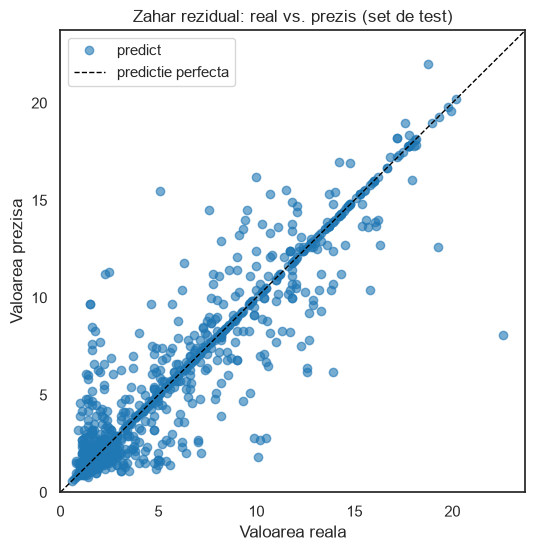

In [16]:
# Valori reale vs. valori prezise pentru zaharul rezidual
sns.set_context('notebook')
sns.set_style('white')
fig = plt.figure(figsize=(6, 6))
ax = plt.axes()

ph_test_predict = pd.DataFrame({'test': y_test.values,
                                'predict': y_test_pred_gr_sugar}).set_index('test').sort_index()

ph_test_predict.plot(marker='o', ls='', ax=ax, alpha=0.6, legend=False)
lims = [0, ph_test_predict.index.max() * 1.05]
ax.plot(lims, lims, 'k--', linewidth=1, label='predictie perfecta')
ax.set(xlabel='Valoarea reala', ylabel='Valoarea prezisa',
       xlim=lims, ylim=lims, title='Zahar rezidual: real vs. prezis (set de test)')
ax.legend();

**Concluzie:** punctele se aseaza in jurul diagonalei, deci arborele de regresie prezice destul de bine zaharul rezidual (cea mai mare parte a informatiei vine din densitate si alcool). Eroarea pe setul de test este mai mare decat pe setul de antrenare, dar ramane in limite rezonabile.

## Întrebarea 6 *(Opțională)*

Această întrebare este opțională, deoarece pentru rezolvarea ei este necesar un program suplimentar de linie de comandă (GraphViz) și o bibliotecă Python (PyDotPlus). GraphViz poate fi instalat cu ajutorul managerului de pachete pe Linux și Mac. Pentru instalarea bibliotecii PyDotPlus se poate folosi fie `pip`, fie `conda` (`conda install -c conda-forge pydotplus`).

După instalarea acestor programe:

* Creați o vizualizare a arborelui de decizii din întrebarea 3, în care s-a prezis culoarea vinului, iar numărul de caracteristici și/sau diviziuni nu este limitat.
* Creați o vizualizare a arborelui de decizie din întrebarea 4, în care s-a prezis culoarea vinului, dar pentru a găsi adâncimea optimă și numărul optim de caracteristici s-a utilizat căutarea pe grilă.

Arborele de decizie din întrebarea 5 va avea, cel mai probabil, prea multe noduri pentru a putea fi vizualizat.

In [17]:
try:
    import pydotplus
    pydotplus_installed = True
    
except:
    print('PyDotPlus must be installed to execute the remainder of the cells associated with this question.')
    print('Please see the instructions for this question for details.')
    pydotplus_installed = False

PyDotPlus must be installed to execute the remainder of the cells associated with this question.
Please see the instructions for this question for details.


In [18]:
# Daca PyDotPlus si GraphViz sunt instalate, generam imaginea cu export_graphviz
if pydotplus_installed:
    dot_data = StringIO()
    export_graphviz(dt, out_file=dot_data, filled=True, feature_names=feature_cols)
    graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
    display(Image(graph.create_png()))

Deoarece PyDotPlus/GraphViz pot sa nu fie instalate, folosim si alternativa din scikit-learn, `sklearn.tree.plot_tree`, care deseneaza arborele direct cu matplotlib (fara programe externe).

Arborele din intrebarea 3 (fara restrictii) - este foarte mare, asa ca afisam doar primele 3 niveluri:

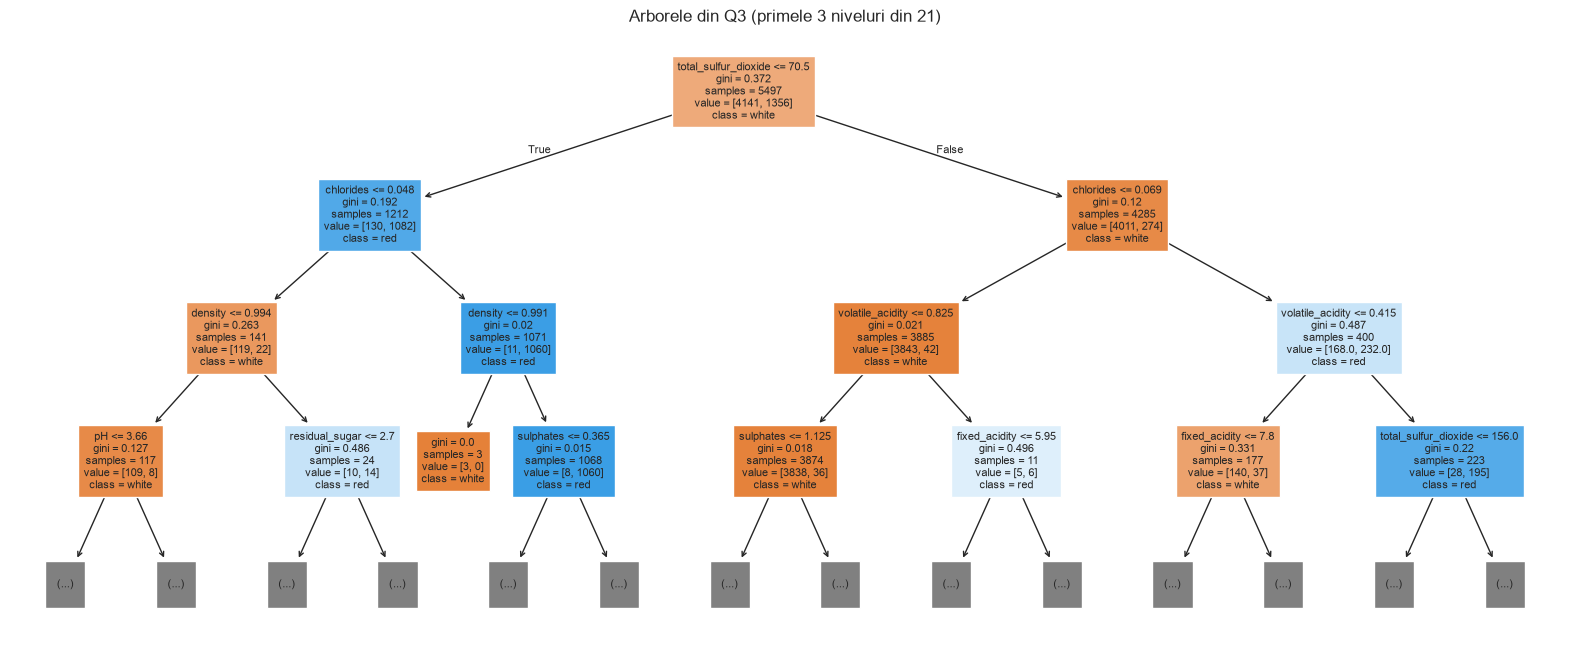

In [19]:
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(dt, feature_names=feature_cols, class_names=['white', 'red'],
          filled=True, max_depth=3, fontsize=8, ax=ax)
ax.set_title('Arborele din Q3 (primele 3 niveluri din %d)' % dt.tree_.max_depth);

Arborele din intrebarea 4 (gasit cu GridSearchCV):

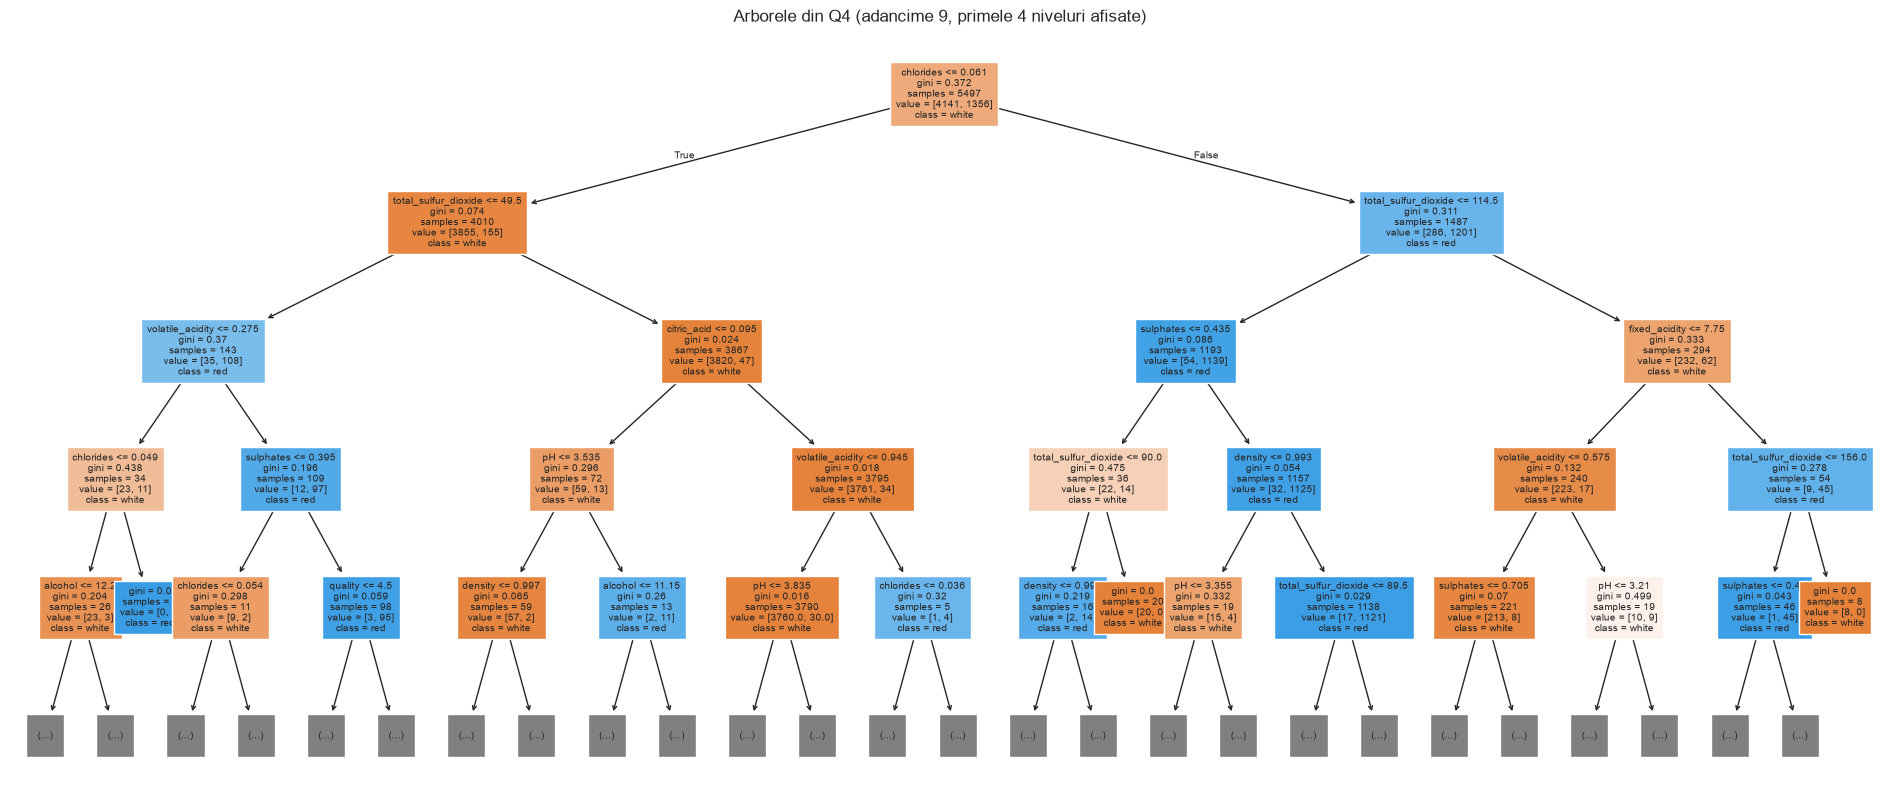

In [20]:
if pydotplus_installed:
    dot_data = StringIO()
    export_graphviz(GR.best_estimator_, out_file=dot_data, filled=True, feature_names=feature_cols)
    graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
    display(Image(graph.create_png()))

best_dt = GR.best_estimator_
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(best_dt, feature_names=feature_cols, class_names=['white', 'red'],
          filled=True, max_depth=4, fontsize=7, ax=ax)
ax.set_title('Arborele din Q4 (adancime %d, primele 4 niveluri afisate)' % best_dt.tree_.max_depth);